In [1]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
import re
from nltk.corpus import stopwords

In [2]:
df = pd.read_csv('Dataset-SA.csv')
df

,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral
...,...,...,...,...,...,...
205047,cello Pack of 18 Opalware Cello Dazzle Lush Fi...,1299,5,must buy!,good product,positive
205048,cello Pack of 18 Opalware Cello Dazzle Lush Fi...,1299,5,super!,nice,positive
205049,cello Pack of 18 Opalware Cello Dazzle Lush Fi...,1299,3,nice,very nice and fast delivery,positive
205050,cello Pack of 18 Opalware Cello Dazzle Lush Fi...,1299,5,just wow!,awesome product,positive


## Data Cleaning

In [3]:
df.isna().sum()

product_name         0
product_price        0
Rate                 0
Review           24664
Summary             11
Sentiment            0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(34375)

In [5]:
df = df.drop_duplicates()

In [6]:
df['Review'] = df['Review'].fillna('')
df['Summary'] = df['Summary'].fillna('')
df['text'] = df['Review'] + ' ' + df['Summary']

In [7]:
df.drop(columns=['product_name','product_price','Rate','Review','Summary'], inplace=True)

In [8]:
df.isna().sum()

Sentiment    0
text         0
dtype: int64

In [9]:
df['Sentiment'].value_counts()

Sentiment
positive    134701
negative     26473
neutral       9503
Name: count, dtype: int64

# Encode Target Labels

In [10]:
df['label'] = df['Sentiment'].str.lower().replace({
    'negative': 0,
    'neutral': 1,
    'positive': 2
})

print(df['label'].value_counts())

label
2    134701
0     26473
1      9503
Name: count, dtype: int64


## Data Preprocessing

In [11]:
stop_words = set(stopwords.words('english'))

def preprocessor(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = text.split()
    tokens = [w for w in tokens if w not in stop_words]
    return tokens

df['tokens'] = df['text'].apply(preprocessor)

In [12]:
token_lengths = df['tokens'].apply(len)
print('Token length stats:')
print(token_lengths.describe())

Token length stats:
count    170677.000000
mean          6.862325
std           7.668795
min           0.000000
25%           3.000000
50%           4.000000
75%           7.000000
max          67.000000
Name: tokens, dtype: float64


In [13]:
df.head()

,Sentiment,text,label,tokens
0,positive,super! great cooler excellent air flow and for...,2,"[super, great, cooler, excellent, air, flow, p..."
1,positive,awesome best budget 2 fit cooler nice cooling,2,"[awesome, best, budget, fit, cooler, nice, coo..."
2,positive,fair the quality is good but the power of air ...,2,"[fair, quality, good, power, air, decent]"
3,negative,useless product very bad product its a only a fan,0,"[useless, product, bad, product, fan]"
4,neutral,fair ok ok product,1,"[fair, ok, ok, product]"


In [14]:
print(f'\n95th percentile: {token_lengths.quantile(0.95):.0f}')
print(f'99th percentile: {token_lengths.quantile(0.99):.0f}')


95th percentile: 22
99th percentile: 45


## Train Word2Vec

In [15]:
from gensim.models import Word2Vec

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [16]:
w2v_model = Word2Vec(
    window=10,      # captures semantic relationships in review text
    min_count=2,    # removes truly rare/noise words
    vector_size=100,  # standard embedding size
    workers=4,
    epochs=10
)

In [17]:
w2v_model.build_vocab(df['tokens'])
print(f'Vocabulary size: {len(w2v_model.wv.index_to_key)}')
print(f'Corpus docs: {w2v_model.corpus_count}, Epochs: {w2v_model.epochs}')

Vocabulary size: 15856
Corpus docs: 170677, Epochs: 10


In [18]:
w2v_model.train(df['tokens'], total_examples=w2v_model.corpus_count, epochs=w2v_model.epochs)

(8139208, 11712410)

In [19]:
print('Most similar to "good":', w2v_model.wv.most_similar('good', topn=5))
print(f'Total unique tokens in Word2Vec: {len(w2v_model.wv.index_to_key)}')

Most similar to "good": [('nice', 0.6972604990005493), ('goodbut', 0.6172292828559875), ('superb', 0.6107842326164246), ('satisfactory', 0.5783630609512329), ('equals', 0.5719969272613525)]
Total unique tokens in Word2Vec: 15856


In [20]:
w2v_model.wv.similarity('good', 'excellent')

np.float32(0.53766143)

In [21]:
w2v_model.wv.similarity('bad', 'poor')

np.float32(0.87018895)

In [22]:
w2v_model.wv.similarity('good', 'bad')

np.float32(0.45588493)

## Build Embedding Matrix

In [23]:
# oov_token handles unknown words at inference time
tokenizer = Tokenizer(oov_token='<OOV>')
tokenizer.fit_on_texts(df['tokens'])
word_index = tokenizer.word_index

print(f'Tokenizer vocab size: {len(word_index)}')
print(f'Word2Vec vocab size:  {len(w2v_model.wv.index_to_key)}')

Tokenizer vocab size: 42768
Word2Vec vocab size:  15856


In [24]:
embedding_dim = 100

embedding_matrix = np.zeros((len(word_index) + 1, embedding_dim))

covered = 0
for word, i in word_index.items():
    if word in w2v_model.wv:
        embedding_matrix[i] = w2v_model.wv[word]
        covered += 1

In [25]:
print(f'\nEmbedding coverage: {covered}/{len(word_index)} words = {covered/len(word_index)*100:.1f}%')
print(f'Words with zero vectors (rare words not in W2V): {len(word_index)-covered}')
print(f'Embedding matrix shape: {embedding_matrix.shape}')


Embedding coverage: 15856/42768 words = 37.1%
Words with zero vectors (rare words not in W2V): 26912
Embedding matrix shape: (42769, 100)


## Prepare Sequences

In [26]:
MAX_LEN = 150   # covers ~95th percentile of token lengths

sequences = tokenizer.texts_to_sequences(df['tokens'])
X = pad_sequences(sequences, maxlen=MAX_LEN, padding='pre', truncating='post')
y = df['label'].values

print(f'X shape: {X.shape}')
print(f'y shape: {y.shape}')
print(f'y distribution: {np.bincount(y)}')

sample_nonzero = np.count_nonzero(X[0])
print(f'Non-zero tokens in sample doc: {sample_nonzero}/{MAX_LEN}')

X shape: (170677, 150)
y shape: (170677,)
y distribution: [ 26473   9503 134701]
Non-zero tokens in sample doc: 10/150


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y   # stratify preserves class ratio
)

print(f'Train size: {X_train.shape[0]}')
print(f'Test  size: {X_test.shape[0]}')

Train size: 136541
Test  size: 34136


## Build Bidirectional LSTM Architecture

In [28]:
NUM_CLASSES = 3   # positive, neutral, negative

model = Sequential()

# Embedding converts integer indices → dense vectors
# trainable=True allows fine-tuning the Word2Vec vectors during LSTM training
model.add(Embedding(
    input_dim=len(word_index) + 1,
    output_dim=embedding_dim,
    weights=[embedding_matrix],
    input_length=MAX_LEN,
    trainable=True
))

# Bidirectional LSTM reads text forwards and backwards
model.add(Bidirectional(LSTM(128, dropout=0.3, recurrent_dropout=0.2)))

model.add(Dropout(0.4))

# Softmax output for multiclass classification (3 classes)
model.add(Dense(NUM_CLASSES, activation='softmax'))

model.build(input_shape=(None, MAX_LEN))

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',   # labels are integers, not one-hot
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 150, 100)            │       4,276,900 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ (None, 256)                 │         234,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 3)                   │             771 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,512,167 (17.21 MB)

 Trainable params: 4,512,167 (17.21 MB)

 Non-trainable params: 0 (0.00 B)

## Train with Callbacks

In [29]:
callbacks = [EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)]

history = model.fit(
    X_train, y_train,
    batch_size=256,
    epochs=5,
    validation_data=(X_test, y_test),
    callbacks=callbacks
)

Epoch 1/5
534/534 ━━━━━━━━━━━━━━━━━━━━ 672s 1s/step - accuracy: 0.9063 - loss: 0.2850 - val_accuracy: 0.9200 - val_loss: 0.2433
Epoch 2/5
534/534 ━━━━━━━━━━━━━━━━━━━━ 773s 1s/step - accuracy: 0.9198 - loss: 0.2403 - val_accuracy: 0.9231 - val_loss: 0.2282
Epoch 3/5
534/534 ━━━━━━━━━━━━━━━━━━━━ 776s 1s/step - accuracy: 0.9250 - loss: 0.2232 - val_accuracy: 0.9247 - val_loss: 0.2224
Epoch 4/5
534/534 ━━━━━━━━━━━━━━━━━━━━ 779s 1s/step - accuracy: 0.9298 - loss: 0.2064 - val_accuracy: 0.9259 - val_loss: 0.2208
Epoch 5/5
534/534 ━━━━━━━━━━━━━━━━━━━━ 985s 2s/step - accuracy: 0.9357 - loss: 0.1879 - val_accuracy: 0.9255 - val_loss: 0.2261


## Evaluate

In [30]:
loss, acc = model.evaluate(X_test, y_test)
print('Test Loss    :', round(loss, 4))
print('Test Accuracy:', round(acc, 4))

1067/1067 ━━━━━━━━━━━━━━━━━━━━ 51s 48ms/step - accuracy: 0.9259 - loss: 0.2208
Test Loss    : 0.2208
Test Accuracy: 0.9259


In [31]:
y_pred = np.argmax(model.predict(X_test), axis=1)

1067/1067 ━━━━━━━━━━━━━━━━━━━━ 39s 36ms/step


In [32]:
print(classification_report(y_test, y_pred, target_names=['Negative', 'Neutral', 'Positive']))

              precision    recall  f1-score   support

    Negative       0.84      0.84      0.84      5295
     Neutral       0.73      0.43      0.54      1900
    Positive       0.95      0.98      0.96     26941

    accuracy                           0.93     34136
   macro avg       0.84      0.75      0.78     34136
weighted avg       0.92      0.93      0.92     34136



In [34]:
import matplotlib.pyplot as plt

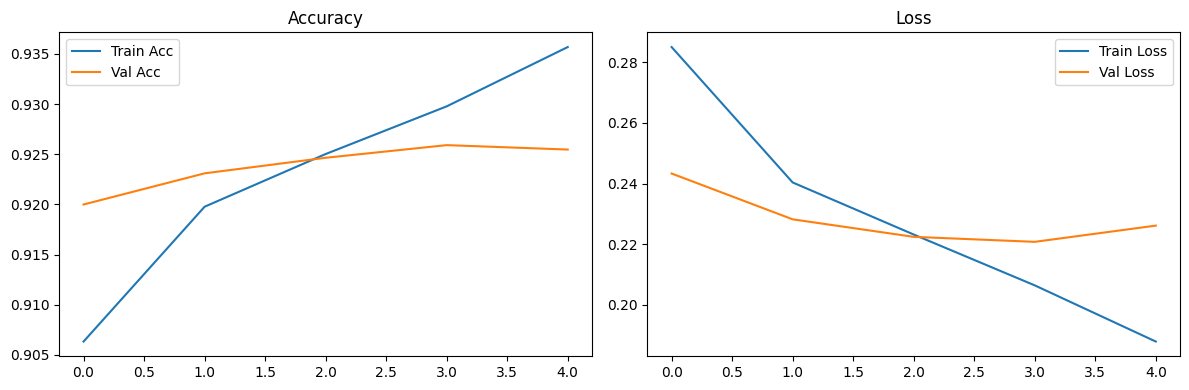

In [35]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history['accuracy'],     label='Train Acc')
ax1.plot(history.history['val_accuracy'], label='Val Acc')
ax1.set_title('Accuracy')
ax1.legend()

ax2.plot(history.history['loss'],     label='Train Loss')
ax2.plot(history.history['val_loss'], label='Val Loss')
ax2.set_title('Loss')
ax2.legend()

plt.tight_layout()
plt.savefig('training_curves2.png', dpi=100)
plt.show()

## Save

In [37]:
import pickle

In [38]:
model.save('sentiment_classifier2.keras')

with open('tokenizer2.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

with open('stopwords2.pkl', 'wb') as f:
    pickle.dump(stop_words, f)

In [55]:
label_map = {
    'negative': 0,
    'neutral': 1,
    'positive': 2
}

In [56]:
import json
config = {'MAX_LEN': MAX_LEN, 'embedding_dim': embedding_dim, 'num_classes': NUM_CLASSES, 'label_map': label_map}
with open('config2.json', 'w') as f:
    json.dump(config, f)

## Testing on New Reviews

In [57]:
reviews = [
    "Excellent product. Highly recommended.",
    "The product is average and works as expected.",
    "Very poor quality. Waste of money."
]

for review in reviews:
    seq = tokenizer.texts_to_sequences([review.split()])
    pad = pad_sequences(seq, maxlen=MAX_LEN)

    probs = model.predict(pad, verbose=0)[0]
    pred = np.argmax(probs)

    print(f"Review: {review}")
    print(f"Negative: {probs[0]:.3f} | Neutral: {probs[1]:.3f} | Positive: {probs[2]:.3f}")
    print(f"Prediction: {label_decode[pred]}\n")

Review: Excellent product. Highly recommended.
Negative: 0.001 | Neutral: 0.059 | Positive: 0.940
Prediction: Positive

Review: The product is average and works as expected.
Negative: 0.209 | Neutral: 0.493 | Positive: 0.298
Prediction: Neutral

Review: Very poor quality. Waste of money.
Negative: 0.971 | Neutral: 0.009 | Positive: 0.020
Prediction: Negative

